# Case file 7 · Lying Clues: the guidance lab

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/07_guidance_lab.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now we use the real, fully trained model (39 million parameters) and turn its knobs: temperature, top-p and the
two guidance strengths. Then we catch guidance in the act: it makes colours more faithful but quietly erases poses.

**Time:** about 4 minutes on a laptop CPU (the model downloads once: 157 MB + 470 MB text encoder).
**You will learn:** softmax with temperature, top-p, classifier-free guidance, split guidance, and how to measure
an effect instead of eyeballing it.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import numpy as np
import torch
from IPython.display import display
from pixelsprite import SpritePipeline, sheet
from pixelsprite.colour import srgb_to_oklab

pipe = SpritePipeline.from_pretrained()          # downloads from Hugging Face the first time
print("running on", pipe.device)

def show(text, title=None, n=12, **kw):
    res = pipe.generate(text, n=n, size=16, seed=kw.pop("seed", 0), **kw)
    display(sheet(res.sprites, title or text, scale=4, cols=12))
    return res

running on cpu


## 1. Temperature: how adventurous is each colour choice?
The model gives a score to each of the 1,024 colours. **Softmax** turns scores into probabilities:
p_i = e^{s_i / T} / Σ_j e^{s_j / T}. A small temperature T sharpens the distribution (the favourite wins more
often); a large T flattens it.

T = 0.5: probabilities [0.865 0.117 0.016 0.002]
T = 1.0: probabilities [0.644 0.237 0.087 0.032]
T = 2.0: probabilities [0.455 0.276 0.167 0.102]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  94%|█████████▍| 187/199 [00:00<00:00, 1861.49it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1929.45it/s]

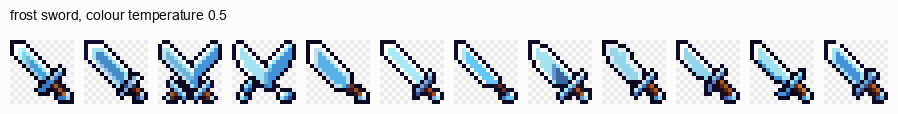

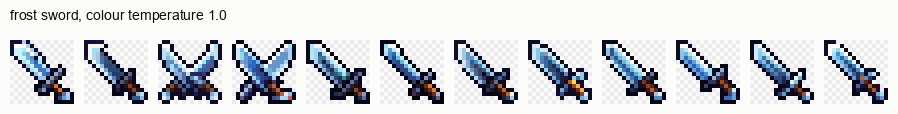

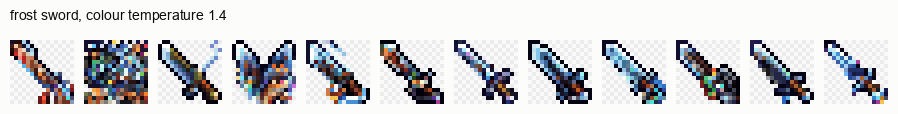

In [3]:
scores = torch.tensor([2.0, 1.0, 0.0, -1.0])
for T in (0.5, 1.0, 2.0):
    print(f"T = {T}: probabilities {torch.softmax(scores / T, 0).numpy().round(3)}")
for T in (0.5, 1.0, 1.4):
    show("frost sword", f"frost sword, colour temperature {T}", temperature=T)

## 2. Guidance on colour
The model is asked twice: with the caption and without it. Guidance pushes the answer away from the caption-free
one: lp = lp_without + g · (lp_with − lp_without) (lp = log-probability of each colour).
g = 0 ignores the text, g = 1 is the plain model, g > 1 exaggerates whatever the caption changes.

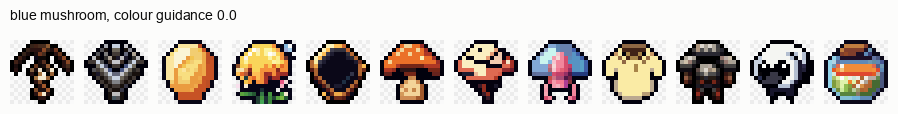

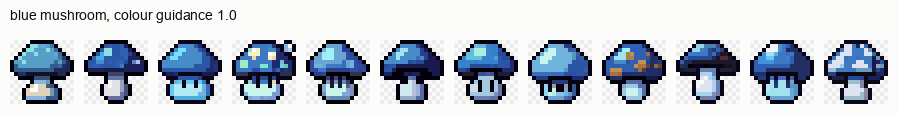

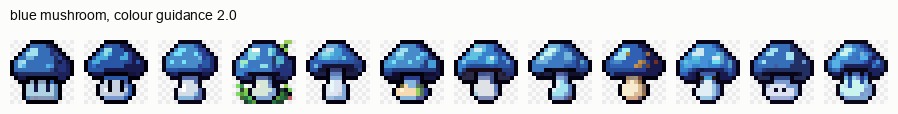

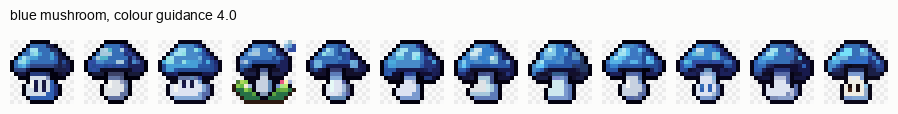

In [4]:
for g in (0.0, 1.0, 2.0, 4.0):
    show("blue mushroom", f"blue mushroom, colour guidance {g}", g_colour=g)

## 3. Measure, don't eyeball: the named-colour test
We find each sprite's dominant hue (the most common hue among its coloured inner pixels) and count how often it
is the colour named in the caption.

In [5]:
PROTOS = {"red": (220, 40, 40), "orange": (240, 140, 30), "yellow": (240, 215, 50), "green": (60, 170, 60),
          "cyan": (40, 190, 200), "blue": (40, 90, 220), "purple": (140, 60, 200), "pink": (240, 120, 180)}
proto_hue = {k: np.arctan2(*srgb_to_oklab(np.array(v, np.uint8))[[2, 1]]) for k, v in PROTOS.items()}

def dominant_hue(rgba):
    m = rgba[..., 3] > 0
    p = np.pad(m, 1); inner = m & p[:-2, 1:-1] & p[2:, 1:-1] & p[1:-1, :-2] & p[1:-1, 2:]
    lab = srgb_to_oklab(rgba[inner if inner.any() else m][:, :3])
    chroma, hue = np.hypot(lab[:, 1], lab[:, 2]), np.arctan2(lab[:, 2], lab[:, 1])
    hue = hue[chroma >= 0.05]
    if len(hue) == 0:
        return "grey"
    names = list(proto_hue)
    d = np.abs(np.angle(np.exp(1j * (hue[:, None] - np.array([proto_hue[k] for k in names])))))
    return names[np.bincount(d.argmin(1), minlength=len(names)).argmax()]

tests = [("blue mushroom", "blue"), ("red potion", "red"), ("green shield", "green"), ("purple crown", "purple")]
for g in (1.0, 2.0):
    hits = [dominant_hue(s) == colour for text, colour in tests for s in pipe.generate(text, 12, 16, seed=1, g_colour=g).sprites]
    print(f"colour guidance {g}: named colour wins in {100 * np.mean(hits):.0f}% of {len(hits)} sprites")

colour guidance 1.0: named colour wins in 81% of 48 sprites


colour guidance 2.0: named colour wins in 85% of 48 sprites


## 4. The lying clue: guidance on shape erases poses
In the data, swords captioned "upright" are mostly vertical. Does the model listen? We measure the direction of
each sword's long axis. Then we raise the **shape** guidance and measure again.

shape guidance 1.0: 53% vertical swords


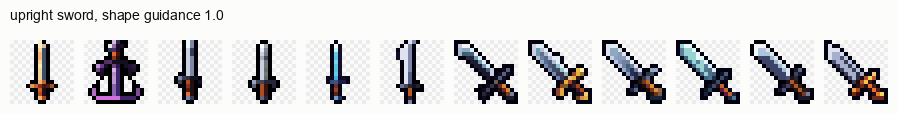

shape guidance 2.0: 3% vertical swords


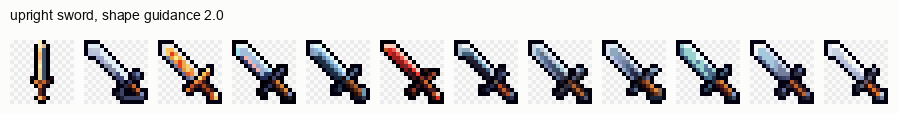

In [6]:
def orientation(mask):
    y, x = np.nonzero(mask)
    y, x = y - y.mean(), -(x - x.mean())
    cov = np.array([[(x * x).mean(), (x * y).mean()], [(x * y).mean(), (y * y).mean()]])
    ev = np.linalg.eigvalsh(cov)
    if ev[1] < 2.5 * max(ev[0], 1e-9):
        return "round"
    angle = np.degrees(0.5 * np.arctan2(2 * cov[0, 1], cov[0, 0] - cov[1, 1]))
    return "vertical" if abs(angle) > 67.5 else "horizontal" if abs(angle) < 22.5 else "diagonal"

for gs in (1.0, 2.0):
    res = pipe.generate("upright sword", 32, 16, seed=3, g_shape=gs, g_colour=2.0)
    v = np.mean([orientation(x >= 0) == "vertical" for x in res.index])
    print(f"shape guidance {gs}: {100 * v:.0f}% vertical swords")
    display(sheet(res.sprites[:12], f"upright sword, shape guidance {gs}", scale=4, cols=12))

## 5. Why split the guidance?
Old way: one g for the whole 1,025-way choice (1,024 colours + EMPTY). New way: two separate choices per pixel.
* **shape**: "empty or not?" Mix the *log-odds* s = log(p_empty / (1 − p_empty)): s = s_u + g_shape·(s_c − s_u);
* **colour**: "which colour, if not empty?" Mix log-probabilities over the 1,024 colours with g_colour.

A worked example for one pixel: with the caption p_empty = 0.30, without it p_empty = 0.50.

In [7]:
import math
logit = lambda p: math.log(p / (1 - p))
sig = lambda s: 1 / (1 + math.exp(-s))
s_c, s_u = logit(0.30), logit(0.50)
for g in (1, 2, 3):
    print(f"g_shape = {g}: p_empty = {sig(s_u + g * (s_c - s_u)):.3f}")
# g = 2 doubles the caption's push on the silhouette: shapes become 'more typical', and rare poses disappear.

g_shape = 1: p_empty = 0.300
g_shape = 2: p_empty = 0.155
g_shape = 3: p_empty = 0.073


## Your turn
1. Find the colour guidance at which "blue mushroom" stops getting better and starts looking strange.
2. Try "sword pointing down" and "tiny crown". Do the words change the shape at all? Measure it.
3. Write a caption in Russian or Ukrainian and check the named-colour test on it.